# Mini-Jev · Phase 0–1: Look at the data, then measure the baseline

**Goal of this notebook:** get clean train/eval splits from the Jev distillation corpus and measure how well an *untrained* small model already copies Jev. Every later version (v1 SFT, v2 distillation, v3 RL) gets compared against the numbers you produce here.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U datasets transformers accelerate

name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 19.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## Config
`MODEL_ID` is the student. Qwen3-1.7B fits a T4 comfortably in fp16 (~3.5 GB). If a newer small Qwen exists that you'd rather use, swap it in, but stay at or below 4B on a T4.

In [2]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-1.7B"
N_TRAIN = 20_000      # rows for v1/v2 training later
N_EVAL = 2_000        # rows for every eval, v0 through v3
SMOKE_N = 32          # quick end-to-end check before the full eval
USE_DRIVE = True      # saves splits + results to Google Drive so a disconnect doesn't lose them
SAVE_DIR = "/content/drive/MyDrive/mini-jev"

In [4]:
import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    SAVE_DIR = "/content/mini-jev"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving to", SAVE_DIR)

Mounted at /content/drive
Saving to /content/drive/MyDrive/mini-jev


# Phase 0 · Look at the data

Every row is one decision Jev made:
- `state`: the situation
- `question`: what's being decided
- `options`: the allowed answers (2 to 16)
- `target`: **Jev's probability for each option**. This is the soft label. v1 will only use its argmax; v2 will use all of it.
- `kind`: `noul` (yes/no), `choice` (pick one), or `score` (0–5 rating)

In [5]:
import numpy as np, pandas as pd
from datasets import load_dataset

ds = load_dataset("SargeDev/jev-distill-corpus-v3")
print(ds)
train_df = ds["train"].to_pandas()
test_df = ds["test_set_30k"].to_pandas()

README.md:   0%|          | 0.00/4.40k [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B /  431MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/9.25M [00:00<?, ?B/s]

calibration.jsonl:   0%|          | 0.00/9.01M [00:00<?, ?B/s]

...

Generating calibration split:   0%|          | 0/13766 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/14261 [00:00<?, ? examples/s]

Generating ood split:   0%|          | 0/13058 [00:00<?, ? examples/s]

Generating test_set_30k split:   0%|          | 0/29955 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 655806
    })
    validation: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 14111
    })
    calibration: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 13766
    })
    test: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 14261
    })
    ood: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 13058
    })
    test_set_30k: Dataset({
        features: ['id', 'kind', 'options', 'target', 'state', 'question', 'domain', 'family', 'source'],
        num_rows: 29955
    })
})


In [6]:
for col in ["kind", "source", "family"]:
    print(train_df[col].value_counts().to_string(), "\n")

kind
noul      341910
choice    163657
score     150239 

source
yuri_v3       443977
yuri_v1       137203
openjev_v2     74626 

family
knowledge     193406
openjev        74626
technical      57797
agent          57702
business       47725
medical        38641
genomics       31350
structured     23599
science        23526
physics        23231
theology       23216
biology        23184
spatial        22966
chemistry      14837 



In [7]:
def show_examples(df, seed=SEED):
    for kind in ["noul", "choice", "score"]:
        sub = df[df["kind"] == kind]
        if len(sub) == 0:
            continue
        r = sub.sample(1, random_state=seed).iloc[0]
        print(f"=== kind={kind} | domain={r['domain']} | source={r['source']}")
        print("STATE:", str(r["state"])[:400])
        print("QUESTION:", r["question"])
        for o, t in zip(r["options"], r["target"]):
            print(f"   {str(o):>24}  {float(t):.2f}")
        print()

In [8]:
show_examples(train_df)

=== kind=noul | domain=medication_safety | source=yuri_v3
STATE: A medication reconciliation continues a medication during documented pregnancy; additionally matches the renal-dosing guideline. Context: in an 82-year-old with CKD, as part of a compliance sweep. Reported by the operator.
QUESTION: Is this scenario one where: a dose adjustment is required?
                      false  0.26
                       true  0.74

=== kind=choice | domain=hypothesis_eval | source=yuri_v3
STATE: An observed correlation explains all observations but forbids no outcome; additionally makes a novel falsifiable prediction. Context: at the thesis defense, with staffing at reduced levels. Reported by the operator.
QUESTION: Verdict for this scenario.
         strongly_supported  0.06
      tentatively_supported  0.55
                unsupported  0.38
               contradicted  0.01

=== kind=score | domain=fact_checking | source=yuri_v3
STATE: A historical assertion cites an internal survey of 12 peo

## Data-quality check

**🧠 Predict:** in the dataset preview, many `memory_relevance` rows from the `yuri_v1` source had a target of exactly `[0.5, 0.5]`. What does a student model learn from a row like that? What happens to the "top label" for v1 SFT?

Answer after you've guessed: a perfectly uniform label carries **no information** and has **no single top answer**. Training on it would teach "always say 50/50," which pollutes both v1 and v2. So we measure how common these are and drop them, along with any row where two options tie for the top spot.

In [9]:
def target_stats(df):
    t = df["target"].apply(lambda x: np.asarray(x, dtype=float))
    k = t.apply(len)
    return pd.DataFrame({
        "k": k,
        "max_p": t.apply(np.max),
        "uniform": t.apply(lambda a: bool(np.allclose(a, 1.0 / len(a), atol=1e-6))),
        "top_tie": t.apply(lambda a: int(np.isclose(a, a.max()).sum()) > 1),
        "sums_to_1": t.apply(lambda a: bool(np.isclose(a.sum(), 1.0, atol=1e-3))),
    }, index=df.index)

def clean(df, name="df"):
    s = target_stats(df)
    report = pd.DataFrame({
        "rows": df.groupby("source").size(),
        "uniform_%": (s["uniform"].groupby(df["source"]).mean() * 100).round(1),
        "top_tie_%": (s["top_tie"].groupby(df["source"]).mean() * 100).round(1),
    })
    print(f"--- {name} quality by source ---")
    print(report.to_string())
    bad_sum = int((~s["sums_to_1"]).sum())
    if bad_sum:
        print(f"WARNING: {bad_sum} rows whose target doesn't sum to 1")
    keep = ~s["uniform"] & ~s["top_tie"] & s["sums_to_1"] & (s["k"] <= 16)
    print(f"Keeping {int(keep.sum()):,} of {len(df):,} rows ({keep.mean():.1%})\n")
    return df[keep].reset_index(drop=True)

In [10]:
train_clean = clean(train_df, "train")
test_clean = clean(test_df, "test_set_30k")

--- train quality by source ---
              rows  uniform_%  top_tie_%
source                                  
openjev_v2   74626        0.8        4.2
yuri_v1     137203      100.0      100.0
yuri_v3     443977        0.3        1.0
Keeping 511,145 of 655,806 rows (77.9%)

--- test_set_30k quality by source ---
             rows  uniform_%  top_tie_%
source                                 
openjev_v2   2319        1.4        5.0
yuri_v1      2260      100.0      100.0
yuri_v3     25376        0.4        1.0
Keeping 27,324 of 29,955 rows (91.2%)



**Write down in your notes:** what share of the data you dropped and from which source. This goes in your README's "Data" section. Catching a data problem before training is exactly the kind of thing worth mentioning in an interview.

## Sample the splits
We take a **stratified** sample: each `(kind, family)` group keeps the same share it has in the full data, so the small sample isn't accidentally all medical or all yes/no questions.

In [11]:
def stratified_sample(df, n, by=("kind", "family"), seed=SEED):
    by = list(by)
    rng = np.random.default_rng(seed)
    parts = []
    for _, g in df.groupby(by, sort=True):
        k = max(1, int(round(len(g) * n / len(df))))
        parts.append(g.sample(min(k, len(g)), random_state=int(rng.integers(1_000_000_000))))
    out = pd.concat(parts)
    if len(out) > n:
        out = out.sample(n, random_state=seed)
    return out.sample(frac=1, random_state=seed).reset_index(drop=True)

def check_no_leakage(a, b):
    key = lambda d: set(d["state"].astype(str) + "||" + d["question"].astype(str))
    id_overlap = len(set(a["id"]) & set(b["id"]))
    text_overlap = len(key(a) & key(b))
    assert id_overlap == 0, f"{id_overlap} shared ids"
    assert text_overlap == 0, f"{text_overlap} shared state+question pairs"
    print("No leakage between train and eval ✓")

In [12]:
train_s = stratified_sample(train_clean, N_TRAIN)
eval_s = stratified_sample(test_clean, N_EVAL)
check_no_leakage(train_s, eval_s)
print(len(train_s), "train rows |", len(eval_s), "eval rows")
print(eval_s["kind"].value_counts().to_string())

train_s.to_parquet(f"{SAVE_DIR}/train_20k.parquet")
eval_s.to_parquet(f"{SAVE_DIR}/eval_2k.parquet")
print("Saved splits ✓  (later notebooks load these, so every version uses identical data)")

No leakage between train and eval ✓
19996 train rows | 1998 eval rows
kind
noul      723
choice    660
score     615
Saved splits ✓  (later notebooks load these, so every version uses identical data)


# Phase 1 · v0 baseline (no training)

## How we read a probability out of an LLM
We show the options as letters (A, B, C…) and ask for one letter. Then, instead of letting the model *generate* text, we look at the **logits for the very next token** and keep only the scores for the valid letters. A softmax over those gives the model's probability for each option.

Why letters: each letter is a single token, so one forward pass gives the whole distribution. This is the same "one forward pass, typed answer" idea Jev is built on.

In [13]:
LETTERS = "ABCDEFGHIJKLMNOP"
INSTRUCTION = ("You are a decision model. Read the situation and the question, "
               "then answer with the single letter of the best option.")

def format_user_message(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}\n\nAnswer with one letter.")

In [14]:
print(format_user_message(eval_s.iloc[0]))

You are a decision model. Read the situation and the question, then answer with the single letter of the best option.

Situation:
A cited figure rounds 14.2% up to 15%; additionally agrees with two independent sources. Context: in the audited section, immediately after go-live. Reported by the review queue.

Question: Verdict for this scenario.

Options:
A. supported
B. partially_supported
C. unsupported
D. contradicted

Answer with one letter.


## Load the student model
fp16, because the T4 has no fast bf16. A 1.7B model only needs ~3.5 GB for inference, so no quantization yet. Quantization comes in Phase 5, where you'll measure what it costs.

In [15]:
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"   # left-pad so the LAST position is the answer slot in every row
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
model.eval()

LETTER_IDS = []
for L in LETTERS:
    ids = tok.encode(L, add_special_tokens=False)
    assert len(ids) == 1, f"Letter {L} is not a single token: {ids}"
    LETTER_IDS.append(ids[0])

def build_prompt(row):
    msgs = [{"role": "user", "content": format_user_message(row)}]
    # enable_thinking=False: Qwen3 would otherwise "think" in text first; we want the answer token directly
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

print(build_prompt(eval_s.iloc[0])[-300:])

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

dependent sources. Context: in the audited section, immediately after go-live. Reported by the review queue.

Question: Verdict for this scenario.

Options:
A. supported
B. partially_supported
C. unsupported
D. contradicted

Answer with one letter.<|im_end|>
<|im_start|>assistant
<think>

</think>




**Look at the printed prompt end.** The model's next token should be the answer letter. If you see an open `<think>` tag at the very end instead, thinking wasn't disabled and the numbers below will be wrong.

In [16]:
@torch.no_grad()
def predict_distributions(df, batch_size=16):
    rows = df.to_dict("records")
    prompts = [build_prompt(r) for r in rows]
    order = np.argsort([len(p) for p in prompts])      # similar lengths per batch = less padding = faster
    dists, letter_mass = [None] * len(rows), [None] * len(rows)
    for s in tqdm(range(0, len(rows), batch_size)):
        idx = order[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to(model.device)
        try:
            logits = model(**enc, logits_to_keep=1).logits[:, -1, :].float()  # only last position: saves ~GBs
        except TypeError:
            logits = model(**enc).logits[:, -1, :].float()
        full = torch.softmax(logits, dim=-1)
        for j, i in enumerate(idx):
            k = len(rows[i]["options"])
            ids = LETTER_IDS[:k]
            dists[i] = torch.softmax(logits[j, ids], dim=-1).cpu().numpy()
            letter_mass[i] = float(full[j, ids].sum())
    return dists, np.array(letter_mass)

## The metrics

All four compare the student to **Jev**, not to real-world truth. Jev is the teacher, so "correct" here means "agrees with Jev." Say this explicitly in your write-up.

- **Agreement:** how often the student's top option equals Jev's top option.
- **Expected accuracy:** Jev's probability for the student's top option, averaged. A softer version of agreement that respects Jev's uncertainty.
- **KL(Jev ‖ student):** how far the student's whole distribution is from Jev's. 0 = identical. This is the number v2 directly trains to shrink.
- **Brier:** squared distance between the two distributions. Like KL, it's minimized only when the student reports Jev's exact probabilities, which is why it's a *proper scoring rule* (and the reward you'll use in v3).
- **ECE (expected calibration error):** bucket predictions by confidence; in each bucket, compare average confidence with average expected accuracy. 0 = perfectly calibrated. If the model says 80% and is right 80% of the time, that bucket contributes nothing.
- **Letter mass:** how much of the model's *total* probability landed on valid letters. Low mass means the model wanted to say something else, i.e., it's not following the format.

In [17]:
def kl_div(q, p, eps=1e-9):
    q, p = np.asarray(q, float), np.asarray(p, float)
    return float(np.sum(q * (np.log(q + eps) - np.log(p + eps))))

def calibration_bins(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    rows = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            rows.append({"bin_lo": i / n_bins, "bin_hi": (i + 1) / n_bins, "n": int(m.sum()),
                         "mean_conf": float(conf[m].mean()), "mean_acc": float(correct[m].mean())})
    bins = pd.DataFrame(rows)
    ece = float((bins["n"] / len(conf) * (bins["mean_acc"] - bins["mean_conf"]).abs()).sum())
    return ece, bins

def evaluate(preds, targets, n_bins=10):
    conf, soft, hard, kls, briers = [], [], [], [], []
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        conf.append(p[a]); soft.append(q[a]); hard.append(float(a == int(np.argmax(q))))
        kls.append(kl_div(q, p)); briers.append(float(np.sum((p - q) ** 2)))
    ece, bins = calibration_bins(conf, soft, n_bins)
    metrics = {"n": len(conf), "agreement": float(np.mean(hard)), "expected_acc": float(np.mean(soft)),
               "mean_conf": float(np.mean(conf)), "ece": ece, "kl": float(np.mean(kls)),
               "brier": float(np.mean(briers))}
    return metrics, bins

In [18]:
import matplotlib.pyplot as plt

def reliability_diagram(bins, title, path=None):
    # one series, so no legend: the title names it; the diagonal is a labelled reference line
    fig, ax = plt.subplots(figsize=(5, 5), dpi=120)
    ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=1.5, ls="--", zorder=1)
    ax.text(0.97, 0.90, "perfect calibration", color="#6b6b6b", fontsize=8, ha="right", rotation=45, rotation_mode="anchor")
    width = (bins["bin_hi"] - bins["bin_lo"]) - 0.012
    ax.bar(bins["bin_lo"] + 0.006, bins["mean_acc"], width=width, align="edge", color="#3b6fb6", zorder=2)
    for _, r in bins.iterrows():
        ax.text(r["bin_lo"] + 0.05, min(r["mean_acc"] + 0.02, 0.97), f"n={int(r['n'])}", ha="center", fontsize=7, color="#555")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Model confidence (top option)"); ax.set_ylabel("Expected accuracy vs. Jev")
    ax.set_title(title, fontsize=11, loc="left")
    ax.grid(color="#e6e6e6", lw=0.8, zorder=0); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

## Smoke test first
Run 32 rows end to end. If something's broken, you find out in 20 seconds, not 15 minutes.

In [19]:
smoke = eval_s.head(SMOKE_N)
d, mass = predict_distributions(smoke)
m, _ = evaluate(d, smoke["target"])
print({k: round(v, 3) if isinstance(v, float) else v for k, v in m.items()})
print("mean letter mass:", round(float(mass.mean()), 3))

  0%|          | 0/2 [00:00<?, ?it/s]

{'n': 32, 'agreement': 0.406, 'expected_acc': 0.33, 'mean_conf': 0.887, 'ece': 0.557, 'kl': 3.974, 'brier': 0.734}
mean letter mass: 0.578


## Full v0 eval

**🧠 Predict before running:** an untrained 1.7B model choosing between ~2–6 options. What agreement do you expect? Is its confidence too high, too low, or about right? Write your guesses down.

In [20]:
v0_dists, v0_mass = predict_distributions(eval_s)
v0_metrics, v0_bins = evaluate(v0_dists, eval_s["target"])
v0_metrics["letter_mass"] = float(v0_mass.mean())
print(pd.Series(v0_metrics).round(4).to_string())

  0%|          | 0/125 [00:00<?, ?it/s]

n               1998.0000
agreement          0.3488
expected_acc       0.3407
mean_conf          0.9303
ece                0.5903
kl                 5.0254
brier              0.8210
letter_mass        0.7249


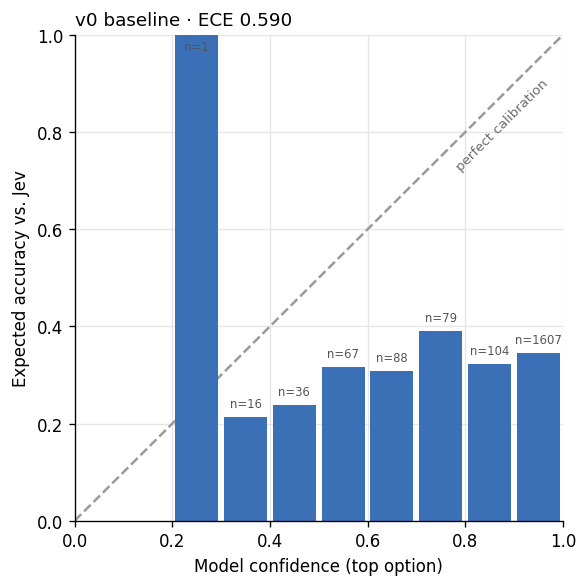

In [21]:
fig = reliability_diagram(v0_bins, f"v0 baseline · ECE {v0_metrics['ece']:.3f}", f"{SAVE_DIR}/reliability_v0.png")
plt.show()

**How to read it:** bars *below* the diagonal mean overconfident (says 90%, right less often). Bars *above* mean underconfident. Bars on the line mean calibrated.

In [22]:
per_kind = []
for kind, g in eval_s.groupby("kind"):
    idx = g.index.to_numpy()
    m, _ = evaluate([v0_dists[i] for i in idx], g["target"])
    per_kind.append({"kind": kind, **m})
print(pd.DataFrame(per_kind).round(3).to_string(index=False))

  kind   n  agreement  expected_acc  mean_conf   ece    kl  brier
choice 660      0.470         0.430      0.867 0.439 3.249  0.601
  noul 723      0.458         0.470      0.975 0.505 4.905  0.729
 score 615      0.091         0.093      0.946 0.853 7.074  1.165


## Save everything
`results.csv` is the table that grows with every version (v0 → v3). It's the core of your write-up.

In [23]:
import datetime
row = {"version": "v0", "model": MODEL_ID, "method": "zero-shot", **v0_metrics,
       "run_at": datetime.datetime.now().isoformat(timespec="minutes")}
res_path = f"{SAVE_DIR}/results.csv"
results = pd.read_csv(res_path) if os.path.exists(res_path) else pd.DataFrame()
results = pd.concat([results[results.get("version", pd.Series(dtype=str)) != "v0"], pd.DataFrame([row])], ignore_index=True)
results.to_csv(res_path, index=False)

out = eval_s[["id", "kind", "domain", "target"]].copy()
out["v0_pred"] = [p.tolist() for p in v0_dists]
out["v0_letter_mass"] = v0_mass
out.to_parquet(f"{SAVE_DIR}/preds_v0.parquet")
print(results.round(4).to_string(index=False))

version           model    method    n  agreement  expected_acc  mean_conf    ece     kl  brier  letter_mass           run_at
     v0 Qwen/Qwen3-1.7B zero-shot 1998     0.3488        0.3407     0.9303 0.5903 5.0254  0.821       0.7249 2026-10-13T16:58


# Your turn (do these before Phase 2)

1. **Compare to your predictions.** Where were you wrong, and why?
2. **Read 10 mistakes.** Filter to rows where v0 was confident (>0.8) but disagreed with Jev. Is the model misreading the task, or are these genuinely ambiguous?
3. **Check letter mass.** If it's well below 1.0, the base model isn't following the format. That alone is something SFT should fix; predict how much.
4. **Write two README paragraphs in your own words:** what ECE measures, and why we compare against Jev rather than ground truth.

Next notebook: **v1 SFT** with QLoRA, loading `train_20k.parquet` from Drive.

In [24]:
pred = np.array([p.argmax() for p in v0_dists])
conf = np.array([p.max() for p in v0_dists])
jev  = np.array([np.argmax(t) for t in eval_s["target"]])

# Task 3: format-following + position bias
print("Mean letter mass:", round(float(v0_mass.mean()), 3))
for k, g in eval_s.groupby("kind"):
    i = g.index.to_numpy()
    print(f"\n{k} | v0 picks: ", pd.Series([LETTERS[a] for a in pred[i]]).value_counts(normalize=True).round(2).to_dict())
    print(f"{k} | Jev picks:", pd.Series([LETTERS[a] for a in jev[i]]).value_counts(normalize=True).round(2).to_dict())

# Task 2: 10 confident mistakes
mask = (conf > 0.8) & (pred != jev)
print(f"\n{mask.sum()} confident mistakes out of {len(mask)}")
for i in np.where(mask)[0][:10]:
    r = eval_s.iloc[i]
    print("=" * 80, f"\n{r['kind']} | {r['domain']}\nSTATE: {str(r['state'])[:300]}\nQ: {r['question']}")
    for j, (o, t) in enumerate(zip(r["options"], r["target"])):
        print(f"  {LETTERS[j]}. {str(o):<25} Jev {t:.2f} | v0 {v0_dists[i][j]:.2f}")

Mean letter mass: 0.725

choice | v0 picks:  {'B': 0.39, 'D': 0.32, 'C': 0.17, 'A': 0.12, 'F': 0.0, 'E': 0.0}
choice | Jev picks: {'B': 0.27, 'A': 0.27, 'D': 0.23, 'C': 0.22, 'E': 0.01, 'G': 0.0, 'F': 0.0, 'H': 0.0}

noul | v0 picks:  {'B': 0.94, 'A': 0.06}
noul | Jev picks: {'A': 0.55, 'B': 0.45}

score | v0 picks:  {'B': 0.91, 'D': 0.07, 'C': 0.01, 'A': 0.0, 'F': 0.0}
score | Jev picks: {'D': 0.41, 'E': 0.36, 'C': 0.08, 'B': 0.07, 'F': 0.06, 'A': 0.02}

1111 confident mistakes out of 1998
noul | observability
STATE: Node pgsql-14 returned to baseline after 11 minutes; additionally shows disk at 91% and climbing 1%/hour. Context: over the last hour, with staffing at reduced levels. Reported by the supervisor.
Q: Is this scenario one where: this can wait until morning?
  A. false                     Jev 0.69 | v0 0.00
  B. true                      Jev 0.31 | v0 1.00
score | doctrinal_reasoning
STATE: A confessional statement follows the ecumenical creeds verbatim; additionally asserts